# Data Cleaning - Theo dõi dữ liệu thay đổi qua từng bước
**Nhóm:** DS66B - Group 10  
**Dataset:** Online Retail II (2009 - 2011)

Notebook này tái hiện **đúng** pipeline làm sạch trong `test_super_final.executed.ipynb` (Bước 1 + Bước 4), nhưng tách từng điều kiện ra riêng để xem dữ liệu thay đổi thế nào sau mỗi bước:

| # | Bước | Thao tác |
| --- | --- | --- |
| 0 | Raw | Gộp 2 sheet Excel |
| 1 | Drop duplicates | Xóa dòng trùng lặp hoàn toàn |
| 2 | Fill missing | Customer ID → 'Guest', Description → 'Unknown' |
| 3 | Ghost buys | Phát hiện đơn mua ảo có đơn hủy đối xứng |
| 4a-4f | Lọc giao dịch | Hủy (C), Adjust (A), ghost, Quantity ≤ 0, Price ≤ 0, StockCode không bắt đầu bằng số |
| 5 | Revenue + gom ngày | Revenue = Quantity × Price, gom theo Date |
| 6 | Bỏ Thứ Bảy | Loại ngày cửa hàng đóng cửa |
| 7 | Log1p | Log_Revenue = log(1 + Revenue) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)

# Nhật ký thay đổi qua từng bước
cleaning_log = []

def revenue_of(d):
    return (d['Quantity'] * d['Price']).sum()

def record(step, before, after, unit='giao dịch', rev_before=None, rev_after=None):
    raw_n = cleaning_log[0]['Số dòng sau'] if cleaning_log else len(before)
    row = {
        'Bước': step,
        'Đơn vị': unit,
        'Số dòng trước': len(before),
        'Bị loại': len(before) - len(after),
        '% bị loại': round((len(before) - len(after)) / len(before) * 100, 3) if len(before) else 0,
        'Số dòng sau': len(after),
        'Còn lại so với Raw (%)': round(len(after) / raw_n * 100, 2) if unit == 'giao dịch' else np.nan,
        'Doanh thu trước (£)': round(rev_before, 2) if rev_before is not None else np.nan,
        'Doanh thu sau (£)': round(rev_after, 2) if rev_after is not None else np.nan,
    }
    cleaning_log.append(row)
    print(f'>>> Sau bước [{step}]: còn lại {len(after):,} {unit} | shape = {after.shape} | bị loại {row["Bị loại"]:,}')
    display(pd.DataFrame([row]))

def overview(d):
    return pd.DataFrame({
        'Dtype': d.dtypes,
        'Missing': d.isnull().sum(),
        'Missing %': (d.isnull().sum() / len(d) * 100).round(3),
        'Unique': d.nunique()
    })

---
## Bước 0: Dữ liệu thô (Raw)

In [ ]:
import os
# Thư mục data và output nằm cùng cấp với file notebook này
DATA_DIR = 'data'
OUTPUT_DIR = 'output'
os.makedirs(OUTPUT_DIR, exist_ok=True)

XLSX_PATH = os.path.join(DATA_DIR, 'online_retail_II.xlsx')
PKL_PATH = os.path.join(DATA_DIR, 'online_retail_II.pkl')

# Chuyển xlsx -> pkl một lần (đọc Excel chậm ~30-45s), các lần sau đọc pkl cho nhanh
if not os.path.exists(PKL_PATH):
    print('Chưa có file pkl, đang chuyển từ xlsx:', os.path.abspath(XLSX_PATH))
    pd.to_pickle(pd.read_excel(XLSX_PATH, sheet_name=None), PKL_PATH)

print('Đọc dữ liệu từ:', os.path.abspath(PKL_PATH))
data = pd.read_pickle(PKL_PATH)

# File pkl có thể lưu dict các sheet hoặc DataFrame đã gộp sẵn
if isinstance(data, dict):
    display(pd.DataFrame({'Sheet': list(data.keys()), 'Số dòng': [len(v) for v in data.values()]}))
    df_raw = pd.concat(data.values(), ignore_index=True)
else:
    df_raw = data.reset_index(drop=True)

print('Shape raw:', df_raw.shape)
display(overview(df_raw))
display(df_raw[['Quantity', 'Price']].describe().T)
cleaning_log.append({'Bước': '0. Raw', 'Đơn vị': 'giao dịch', 'Số dòng trước': len(df_raw), 'Số dòng sau': len(df_raw),
                     'Bị loại': 0, '% bị loại': 0.0, 'Doanh thu trước (£)': round(revenue_of(df_raw), 2),
                     'Doanh thu sau (£)': round(revenue_of(df_raw), 2)})

---
## Bước 1: Xóa dòng trùng lặp hoàn toàn

In [3]:
dup_mask = df_raw.duplicated(keep=False)
print('Ví dụ các dòng bị trùng (hiển thị cả bản gốc và bản lặp):')
display(df_raw[dup_mask].sort_values(['Invoice', 'StockCode']).head(10))

df = df_raw.drop_duplicates()
record('1. Drop duplicates', df_raw, df, rev_before=revenue_of(df_raw), rev_after=revenue_of(df))

Ví dụ các dòng bị trùng (hiển thị cả bản gốc và bản lặp):


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom


>>> Sau bước [1. Drop duplicates]: còn lại 1,033,036 giao dịch | shape = (1033036, 8) | bị loại 34,335


,Bước,Đơn vị,Số dòng trước,Bị loại,% bị loại,Số dòng sau,Còn lại so với Raw (%),Doanh thu trước (£),Doanh thu sau (£)
0,1. Drop duplicates,giao dịch,1067371,34335,3.217,1033036,96.78,19287250.57,18855533.7


---
## Bước 2: Điền giá trị khuyết
Không xóa dòng, chỉ thay đổi giá trị: Customer ID khuyết → 'Guest', Description khuyết → 'Unknown'.

In [4]:
df_before = df.copy()
missing_before = df.isnull().sum()

df['Customer ID'] = df['Customer ID'].fillna('Guest')
df['Description'] = df['Description'].fillna('Unknown')

display(pd.DataFrame({'Missing trước': missing_before, 'Missing sau': df.isnull().sum()}))
print('Ví dụ dòng đã được điền:')
display(df[df_before['Customer ID'].isnull() & df_before['Description'].isnull()].head(5))
record('2. Fill missing', df_before, df, rev_before=revenue_of(df_before), rev_after=revenue_of(df))

,Missing trước,Missing sau
Invoice,0,0
StockCode,0,0
Description,4275,0
Quantity,0,0
InvoiceDate,0,0
Price,0,0
Customer ID,235151,0
Country,0,0


Ví dụ dòng đã được điền:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
470,489521,21646,Unknown,-50,2009-12-01 11:44:00,0.0,Guest,United Kingdom
3114,489655,20683,Unknown,-44,2009-12-01 17:26:00,0.0,Guest,United Kingdom
3161,489659,21350,Unknown,230,2009-12-01 17:39:00,0.0,Guest,United Kingdom
3731,489781,84292,Unknown,17,2009-12-02 11:45:00,0.0,Guest,United Kingdom
4296,489806,18010,Unknown,-770,2009-12-02 12:42:00,0.0,Guest,United Kingdom


>>> Sau bước [2. Fill missing]: còn lại 1,033,036 giao dịch | shape = (1033036, 8) | bị loại 0


,Bước,Đơn vị,Số dòng trước,Bị loại,% bị loại,Số dòng sau,Còn lại so với Raw (%),Doanh thu trước (£),Doanh thu sau (£)
0,2. Fill missing,giao dịch,1033036,0,0.0,1033036,96.78,18855533.7,18855533.7


---
## Bước 3: Phát hiện đơn mua 'ảo' có đơn hủy đối xứng (Ghost Cancellation Pairs)
Đơn mua > 100 sản phẩm khớp với đơn hủy cùng Customer ID, cùng StockCode và đúng số lượng tuyệt đối.

In [5]:
df['Is_Cancelled'] = df['Invoice'].astype(str).str.startswith('C')

cancels = df[df['Quantity'] < 0].copy()
cancels['Abs_Qty'] = cancels['Quantity'].abs()
big_cancels = cancels[cancels['Abs_Qty'] > 100]
big_buys = df[df['Quantity'] > 100]

matched_cancels = pd.merge(big_buys, big_cancels, on=['Customer ID', 'StockCode'], suffixes=('_buy', '_cancel'))
matched = matched_cancels[matched_cancels['Quantity_buy'] == matched_cancels['Abs_Qty']]
ghost_buys = matched['Invoice_buy'].unique()

print(f'Số hóa đơn mua ảo phát hiện: {len(ghost_buys)}')
pairs = matched[['Customer ID', 'StockCode', 'Invoice_buy', 'InvoiceDate_buy', 'Quantity_buy', 'Price_buy',
                 'Invoice_cancel', 'InvoiceDate_cancel', 'Quantity_cancel']].copy()
pairs['Revenue_buy (£)'] = pairs['Quantity_buy'] * pairs['Price_buy']
print('Top 10 cặp mua - hủy đối xứng có giá trị lớn nhất:')
display(pairs.sort_values('Revenue_buy (£)', ascending=False).head(10).reset_index(drop=True))

Số hóa đơn mua ảo phát hiện: 283
Top 10 cặp mua - hủy đối xứng có giá trị lớn nhất:


,Customer ID,StockCode,Invoice_buy,InvoiceDate_buy,Quantity_buy,Price_buy,Invoice_cancel,InvoiceDate_cancel,Quantity_cancel,Revenue_buy (£)
0,16446.0,23843,581483,2011-12-09 09:15:00,80995,2.08,C581484,2011-12-09 09:27:00,-80995,168469.60
1,12346.0,23166,541431,2011-01-18 10:01:00,74215,1.04,C541433,2011-01-18 10:17:00,-74215,77183.60
2,15838.0,84347,530715,2010-11-04 11:36:00,9360,1.69,C536757,2010-12-02 14:23:00,-9360,15818.40
3,15749.0,21108,540815,2011-01-11 12:55:00,3114,2.10,C550456,2011-04-18 13:08:00,-3114,6539.40
4,15749.0,21108,550461,2011-04-18 13:20:00,3114,2.10,C550456,2011-04-18 13:08:00,-3114,6539.40
5,15749.0,85123A,540815,2011-01-11 12:55:00,1930,2.55,C550456,2011-04-18 13:08:00,-1930,4921.50
6,15749.0,85123A,550461,2011-04-18 13:20:00,1930,2.40,C550456,2011-04-18 13:08:00,-1930,4632.00
7,15749.0,48185,540818,2011-01-11 12:57:00,670,6.75,C550456,2011-04-18 13:08:00,-670,4522.50
8,15749.0,48185,550461,2011-04-18 13:20:00,670,6.35,C550456,2011-04-18 13:08:00,-670,4254.50
9,17450.0,23113,567423,2011-09-20 11:05:00,756,5.06,C567527,2011-09-21 09:16:00,-756,3825.36


In [ ]:
# Trực quan hóa: doanh thu theo ngày khi GIỮ vs BỎ đơn mua ảo (các điều kiện lọc khác giữ nguyên)
base = df[
    (~df['Is_Cancelled']) &
    (~df['Invoice'].astype(str).str.startswith(('C', 'A'))) &
    (df['Quantity'] > 0) & (df['Price'] > 0) &
    (df['StockCode'].astype(str).str.match(r'^[0-9]'))
].copy()
base['Revenue'] = base['Quantity'] * base['Price']
base['Date'] = base['InvoiceDate'].dt.normalize()

rev_keep = base.groupby('Date')['Revenue'].sum()
rev_drop = base[~base['Invoice'].isin(ghost_buys)].groupby('Date')['Revenue'].sum().reindex(rev_keep.index, fill_value=0)

# Cửa sổ 3 tuần quanh cặp ghost lớn nhất
top_date = pairs.sort_values('Revenue_buy (£)', ascending=False)['InvoiceDate_buy'].iloc[0].normalize()
win = (rev_keep.index >= top_date - pd.Timedelta(days=21)) & (rev_keep.index <= top_date + pd.Timedelta(days=3))

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].plot(rev_keep.index, rev_keep.values, color='crimson', alpha=0.6, label='Giữ đơn ảo')
axes[0].plot(rev_drop.index, rev_drop.values, color='steelblue', alpha=0.8, label='Bỏ đơn ảo')
axes[0].set_title('Doanh thu theo ngày toàn giai đoạn', fontweight='bold')
axes[0].set_ylabel('Doanh thu (£)')
axes[0].legend()

axes[1].plot(rev_keep.index[win], rev_keep.values[win], color='crimson', marker='o', label='Giữ đơn ảo')
axes[1].plot(rev_drop.index[win], rev_drop.values[win], color='steelblue', marker='o', label='Bỏ đơn ảo')
axes[1].annotate(f"Chênh lệch £{rev_keep[top_date] - rev_drop[top_date]:,.0f}",
                 (top_date, rev_keep[top_date]), xytext=(-160, -10), textcoords='offset points',
                 arrowprops=dict(arrowstyle='->'), fontweight='bold')
axes[1].set_title(f'Phóng to quanh ngày {top_date:%d/%m/%Y}', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

diff = (rev_keep - rev_drop)
display(diff[diff > 0].sort_values(ascending=False).head(10).rename('Doanh thu ảo bị loại (£)').to_frame())

---
## Bước 4: Lọc giao dịch bán hợp lệ
Notebook gốc áp dụng 6 điều kiện cùng lúc. Ở đây áp dụng **lần lượt** từng điều kiện (kết quả cuối giống hệt vì là phép AND) để thấy mỗi điều kiện loại bao nhiêu dòng.

In [6]:
filters = [
    ('4a. Bỏ hóa đơn hủy (Is_Cancelled)', lambda d: ~d['Is_Cancelled']),
    ("4b. Bỏ Invoice bắt đầu 'C'/'A'", lambda d: ~d['Invoice'].astype(str).str.startswith(('C', 'A'))),
    ('4c. Bỏ đơn mua ảo (ghost)', lambda d: ~d['Invoice'].isin(ghost_buys)),
    ('4d. Quantity > 0', lambda d: d['Quantity'] > 0),
    ('4e. Price > 0', lambda d: d['Price'] > 0),
    ('4f. StockCode bắt đầu bằng số', lambda d: d['StockCode'].astype(str).str.match(r'^[0-9]')),
]

df_stage = df.copy()
for name, cond in filters:
    mask = cond(df_stage)
    removed = df_stage[~mask]
    after = df_stage[mask]
    print(f'\n===== {name} =====')
    record(name, df_stage, after, rev_before=revenue_of(df_stage), rev_after=revenue_of(after))
    if len(removed):
        print('Ví dụ dòng bị loại:')
        display(removed[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'InvoiceDate', 'Customer ID']].head(5))
    df_stage = after

df_clean = df_stage.copy()
print('\nShape sau khi lọc:', df_clean.shape)


===== 4a. Bỏ hóa đơn hủy (Is_Cancelled) =====
>>> Sau bước [4a. Bỏ hóa đơn hủy (Is_Cancelled)]: còn lại 1,013,932 giao dịch | shape = (1013932, 9) | bị loại 19,104


,Bước,Đơn vị,Số dòng trước,Bị loại,% bị loại,Số dòng sau,Còn lại so với Raw (%),Doanh thu trước (£),Doanh thu sau (£)
0,4a. Bỏ hóa đơn hủy (Is_Cancelled),giao dịch,1033036,19104,1.849,1013932,94.99,18855533.7,20317584.31


Ví dụ dòng bị loại:


,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,Customer ID
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2.95,2009-12-01 10:33:00,16321.0
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,1.65,2009-12-01 10:33:00,16321.0
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,4.25,2009-12-01 10:33:00,16321.0
181,C489449,21896,POTTING SHED TWINE,-6,2.10,2009-12-01 10:33:00,16321.0
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2.95,2009-12-01 10:33:00,16321.0



===== 4b. Bỏ Invoice bắt đầu 'C'/'A' =====
>>> Sau bước [4b. Bỏ Invoice bắt đầu 'C'/'A']: còn lại 1,013,926 giao dịch | shape = (1013926, 9) | bị loại 6


...


===== 4f. StockCode bắt đầu bằng số =====
>>> Sau bước [4f. StockCode bắt đầu bằng số]: còn lại 999,032 giao dịch | shape = (999032, 9) | bị loại 4,690


,Bước,Đơn vị,Số dòng trước,Bị loại,% bị loại,Số dòng sau,Còn lại so với Raw (%),Doanh thu trước (£),Doanh thu sau (£)
0,4f. StockCode bắt đầu bằng số,giao dịch,1003722,4690,0.467,999032,93.6,19395507.18,18573834.67


Ví dụ dòng bị loại:


,Invoice,StockCode,Description,Quantity,Price,InvoiceDate,Customer ID
89,489439,POST,POSTAGE,3,18.0,2009-12-01 09:28:00,12682.0
126,489444,POST,POSTAGE,1,141.0,2009-12-01 09:55:00,12636.0
173,489447,POST,POSTAGE,1,130.0,2009-12-01 10:10:00,12362.0
625,489526,POST,POSTAGE,6,18.0,2009-12-01 11:50:00,12533.0
1244,489557,POST,POSTAGE,4,18.0,2009-12-01 12:52:00,12490.0



Shape sau khi lọc: (999032, 9)


In [7]:
# So sánh phân phối Quantity & Price: Raw vs Sau lọc
compare = pd.concat({
    'Quantity (raw)': df_raw['Quantity'].describe(),
    'Quantity (clean)': df_clean['Quantity'].describe(),
    'Price (raw)': df_raw['Price'].describe(),
    'Price (clean)': df_clean['Price'].describe(),
}, axis=1)
display(compare.round(3))

# Các StockCode dịch vụ bị loại bởi RegEx
non_product = df[~df['StockCode'].astype(str).str.match(r'^[0-9]')]
print('Các StockCode không phải sản phẩm bị loại (top 15):')
display(non_product.groupby('StockCode').agg(So_dong=('Invoice', 'size'), Mo_ta=('Description', 'first'))
        .sort_values('So_dong', ascending=False).head(15))
display(overview(df_clean))

,Quantity (raw),Quantity (clean),Price (raw),Price (clean)
count,1067371.000,999032.000,1067371.000,999032.000
mean,9.939,10.341,4.649,3.343
std,172.706,57.585,123.553,4.760
min,-80995.000,1.000,-53594.360,0.030
25%,1.000,1.000,1.250,1.250
50%,3.000,4.000,2.100,2.100
75%,10.000,12.000,4.150,4.130
max,80995.000,12960.000,38970.000,1157.150


Các StockCode không phải sản phẩm bị loại (top 15):


,So_dong,Mo_ta
StockCode,,
POST,2086,POSTAGE
DOT,1425,DOTCOM POSTAGE
M,1387,Manual
C2,277,CARRIAGE
D,173,Discount
S,101,SAMPLES
BANK CHARGES,100,Bank Charges
ADJUST,67,Adjustment by john on 26/01/2010 16
AMAZONFEE,36,AMAZON FEE


,Dtype,Missing,Missing %,Unique
Invoice,object,0,0.0,39271
StockCode,object,0,0.0,4876
Description,object,0,0.0,5352
Quantity,int64,0,0.0,484
InvoiceDate,datetime64[us],0,0.0,36514
Price,float64,0,0.0,681
Customer ID,object,0,0.0,5850
Country,str,0,0.0,43
Is_Cancelled,bool,0,0.0,1


---
## Bước 5: Tính Revenue & gom nhóm theo ngày
Đơn vị dữ liệu đổi từ **giao dịch** sang **ngày**.

In [8]:
df_clean['Revenue'] = df_clean['Quantity'] * df_clean['Price']
df_clean['Date'] = pd.to_datetime(df_clean['InvoiceDate'].dt.date)
print('Dữ liệu cấp giao dịch (có thêm Revenue, Date):')
display(df_clean[['Invoice', 'StockCode', 'Quantity', 'Price', 'Revenue', 'InvoiceDate', 'Date']].head())

daily_sales = df_clean.groupby('Date')['Revenue'].sum().reset_index()
print('Dữ liệu cấp ngày:')
display(daily_sales.head())

row = {'Bước': '5. Gom theo ngày', 'Đơn vị': 'giao dịch → ngày', 'Số dòng trước': len(df_clean),
       'Số dòng sau': len(daily_sales), 'Bị loại': np.nan, '% bị loại': np.nan,
       'Doanh thu trước (£)': round(df_clean['Revenue'].sum(), 2), 'Doanh thu sau (£)': round(daily_sales['Revenue'].sum(), 2)}
cleaning_log.append(row)
display(pd.DataFrame([row]))

Dữ liệu cấp giao dịch (có thêm Revenue, Date):


,Invoice,StockCode,Quantity,Price,Revenue,InvoiceDate,Date
0,489434,85048,12,6.95,83.4,2009-12-01 07:45:00,2009-12-01
1,489434,79323P,12,6.75,81.0,2009-12-01 07:45:00,2009-12-01
2,489434,79323W,12,6.75,81.0,2009-12-01 07:45:00,2009-12-01
3,489434,22041,48,2.10,100.8,2009-12-01 07:45:00,2009-12-01
4,489434,21232,24,1.25,30.0,2009-12-01 07:45:00,2009-12-01


Dữ liệu cấp ngày:


,Date,Revenue
0,2009-12-01,52429.13
1,2009-12-02,61873.10
2,2009-12-03,56596.16
3,2009-12-04,39349.21
4,2009-12-05,9042.36


,Bước,Đơn vị,Số dòng trước,Số dòng sau,Bị loại,% bị loại,Doanh thu trước (£),Doanh thu sau (£)
0,5. Gom theo ngày,giao dịch → ngày,999032,604,NaN,NaN,18573834.67,18573834.67


In [ ]:
# Trực quan hóa chuỗi doanh thu theo ngày sau khi làm sạch
ts = daily_sales.set_index('Date')['Revenue']
fig, ax = plt.subplots(figsize=(18, 5))
ax.plot(ts.index, ts.values, color='steelblue', linewidth=1, alpha=0.7, label='Doanh thu ngày')
ax.plot(ts.index, ts.rolling(14, min_periods=1).mean(), color='darkorange', linewidth=2.5, label='Trung bình trượt 14 ngày')
for y in sorted(ts.index.year.unique()):
    ax.axvspan(pd.Timestamp(y, 11, 1), pd.Timestamp(y, 11, 30), color='crimson', alpha=0.08)
ax.set_title('Chuỗi doanh thu theo ngày sau làm sạch (vùng đỏ: tháng 11)', fontweight='bold')
ax.set_ylabel('Doanh thu (£)')
ax.legend()
plt.tight_layout()
plt.show()

---
## Bước 6: Loại bỏ Thứ Bảy (ngày đóng cửa)

In [9]:
day_names = {0: 'Thứ 2', 1: 'Thứ 3', 2: 'Thứ 4', 3: 'Thứ 5', 4: 'Thứ 6', 5: 'Thứ 7', 6: 'Chủ Nhật'}
daily_before = daily_sales.copy()

daily_sales['DayOfWeek'] = daily_sales['Date'].dt.dayofweek
count_before = daily_sales['DayOfWeek'].map(day_names).value_counts()
daily_sales = daily_sales[daily_sales['DayOfWeek'] != 5].copy()
count_after = daily_sales['DayOfWeek'].map(day_names).value_counts()
daily_sales.drop(columns=['DayOfWeek'], inplace=True)
daily_sales = daily_sales.sort_values('Date').reset_index(drop=True)

display(pd.DataFrame({'Số ngày trước': count_before, 'Số ngày sau': count_after})
        .reindex(day_names.values()).fillna(0).astype(int))
record('6. Bỏ Thứ Bảy', daily_before, daily_sales, unit='ngày',
       rev_before=daily_before['Revenue'].sum(), rev_after=daily_sales['Revenue'].sum())

,Số ngày trước,Số ngày sau
DayOfWeek,,
Thứ 2,94,94
Thứ 3,104,104
Thứ 4,104,104
Thứ 5,103,103
Thứ 6,99,99
Thứ 7,1,0
Chủ Nhật,99,99


>>> Sau bước [6. Bỏ Thứ Bảy]: còn lại 603 ngày | shape = (603, 2) | bị loại 1


,Bước,Đơn vị,Số dòng trước,Bị loại,% bị loại,Số dòng sau,Còn lại so với Raw (%),Doanh thu trước (£),Doanh thu sau (£)
0,6. Bỏ Thứ Bảy,ngày,604,1,0.166,603,NaN,18573834.67,18564792.31


In [ ]:
# Trực quan hóa: số ngày & doanh thu trung bình theo thứ, trước vs sau khi bỏ Thứ Bảy
order = list(day_names.values())
db = daily_before.assign(Thu=daily_before['Date'].dt.dayofweek.map(day_names))
da = daily_sales.assign(Thu=daily_sales['Date'].dt.dayofweek.map(day_names))

# Lịch đầy đủ để thấy Thứ Bảy gần như không có giao dịch (doanh thu = 0)
full = pd.DataFrame({'Date': pd.date_range(daily_before['Date'].min(), daily_before['Date'].max())})
full = full.merge(daily_before, on='Date', how='left').fillna({'Revenue': 0})
full['Thu'] = full['Date'].dt.dayofweek.map(day_names)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
pd.DataFrame({'Trước': db['Thu'].value_counts(), 'Sau': da['Thu'].value_counts()}).reindex(order).fillna(0) \
    .plot(kind='bar', ax=axes[0], color=['salmon', 'steelblue'], rot=0)
axes[0].set_title('Số ngày có giao dịch theo thứ', fontweight='bold')

zero_share = full.groupby('Thu')['Revenue'].apply(lambda s: (s == 0).mean() * 100).reindex(order)
zero_share.plot(kind='bar', ax=axes[1], color='gray', rot=0)
axes[1].set_title('% ngày doanh thu = 0 (lịch đầy đủ)', fontweight='bold')
axes[1].set_ylabel('%')

pd.DataFrame({'Trước': db.groupby('Thu')['Revenue'].mean(), 'Sau': da.groupby('Thu')['Revenue'].mean()}).reindex(order).fillna(0) \
    .plot(kind='bar', ax=axes[2], color=['salmon', 'steelblue'], rot=0)
axes[2].set_title('Doanh thu trung bình theo thứ (£)', fontweight='bold')
plt.tight_layout()
plt.show()

---
## Bước 7: Biến đổi Log1p
Không đổi số dòng, chỉ đổi phân phối của biến mục tiêu.

,Revenue (£),Log_Revenue
Mean,30787.3836,10.2097
Std,15574.4546,0.5186
Skewness,1.2914,-0.5001
Kurtosis,2.4285,1.0026


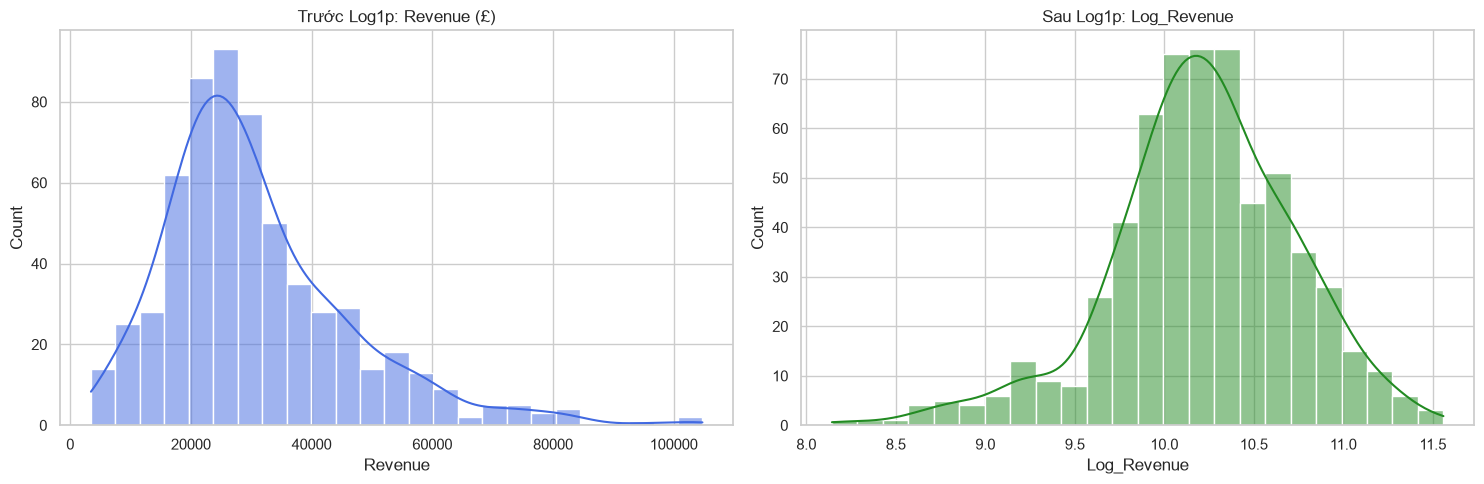

,Revenue,Log_Revenue
Date,,
2009-12-01,52429.13,10.867237
2009-12-02,61873.10,11.032857
2009-12-03,56596.16,10.943714
2009-12-04,39349.21,10.580257
2009-12-06,24285.02,10.097656


In [10]:
daily_sales['Log_Revenue'] = np.log1p(daily_sales['Revenue'])
daily_sales.set_index('Date', inplace=True)

display(pd.DataFrame({
    'Revenue (£)': [daily_sales['Revenue'].mean(), daily_sales['Revenue'].std(), daily_sales['Revenue'].skew(), daily_sales['Revenue'].kurt()],
    'Log_Revenue': [daily_sales['Log_Revenue'].mean(), daily_sales['Log_Revenue'].std(), daily_sales['Log_Revenue'].skew(), daily_sales['Log_Revenue'].kurt()],
}, index=['Mean', 'Std', 'Skewness', 'Kurtosis']).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(daily_sales['Revenue'], kde=True, ax=axes[0], color='royalblue').set_title('Trước Log1p: Revenue (£)')
sns.histplot(daily_sales['Log_Revenue'], kde=True, ax=axes[1], color='forestgreen').set_title('Sau Log1p: Log_Revenue')
plt.tight_layout()
plt.show()
display(daily_sales.head())

---
## Tổng kết: Dữ liệu thay đổi qua toàn bộ pipeline

,Bước,Đơn vị,Số dòng trước,Số dòng sau,Bị loại,% bị loại,Doanh thu trước (£),Doanh thu sau (£),Còn lại so với Raw (%)
0,0. Raw,giao dịch,1067371,1067371,0.0,0.000,19287250.57,19287250.57,NaN
1,1. Drop duplicates,giao dịch,1067371,1033036,34335.0,3.217,19287250.57,18855533.70,96.78
2,2. Fill missing,giao dịch,1033036,1033036,0.0,0.000,18855533.70,18855533.70,96.78
3,4a. Bỏ hóa đơn hủy (Is_Cancelled),giao dịch,1033036,1013932,19104.0,1.849,18855533.70,20317584.31,94.99
4,4b. Bỏ Invoice bắt đầu 'C'/'A',giao dịch,1013932,1013926,6.0,0.001,20317584.31,20465198.39,94.99
5,4c. Bỏ đơn mua ảo (ghost),giao dịch,1013926,1009696,4230.0,0.417,20465198.39,19395507.18,94.60
6,4d. Quantity > 0,giao dịch,1009696,1006303,3393.0,0.336,19395507.18,19395507.18,94.28
7,4e. Price > 0,giao dịch,1006303,1003722,2581.0,0.256,19395507.18,19395507.18,94.04
8,4f. StockCode bắt đầu bằng số,giao dịch,1003722,999032,4690.0,0.467,19395507.18,18573834.67,93.60
9,5. Gom theo ngày,giao dịch → ngày,999032,604,NaN,NaN,18573834.67,18573834.67,NaN


LƯỢNG DỮ LIỆU CÒN LẠI SAU MỖI BƯỚC:


,Bước,Đơn vị,Số dòng trước,Bị loại,Số dòng sau,Còn lại so với Raw (%)
0,0. Raw,giao dịch,1067371,0.0,1067371,NaN
1,1. Drop duplicates,giao dịch,1067371,34335.0,1033036,96.78
2,2. Fill missing,giao dịch,1033036,0.0,1033036,96.78
3,4a. Bỏ hóa đơn hủy (Is_Cancelled),giao dịch,1033036,19104.0,1013932,94.99
4,4b. Bỏ Invoice bắt đầu 'C'/'A',giao dịch,1013932,6.0,1013926,94.99
5,4c. Bỏ đơn mua ảo (ghost),giao dịch,1013926,4230.0,1009696,94.60
6,4d. Quantity > 0,giao dịch,1009696,3393.0,1006303,94.28
7,4e. Price > 0,giao dịch,1006303,2581.0,1003722,94.04
8,4f. StockCode bắt đầu bằng số,giao dịch,1003722,4690.0,999032,93.60
9,5. Gom theo ngày,giao dịch → ngày,999032,NaN,604,NaN


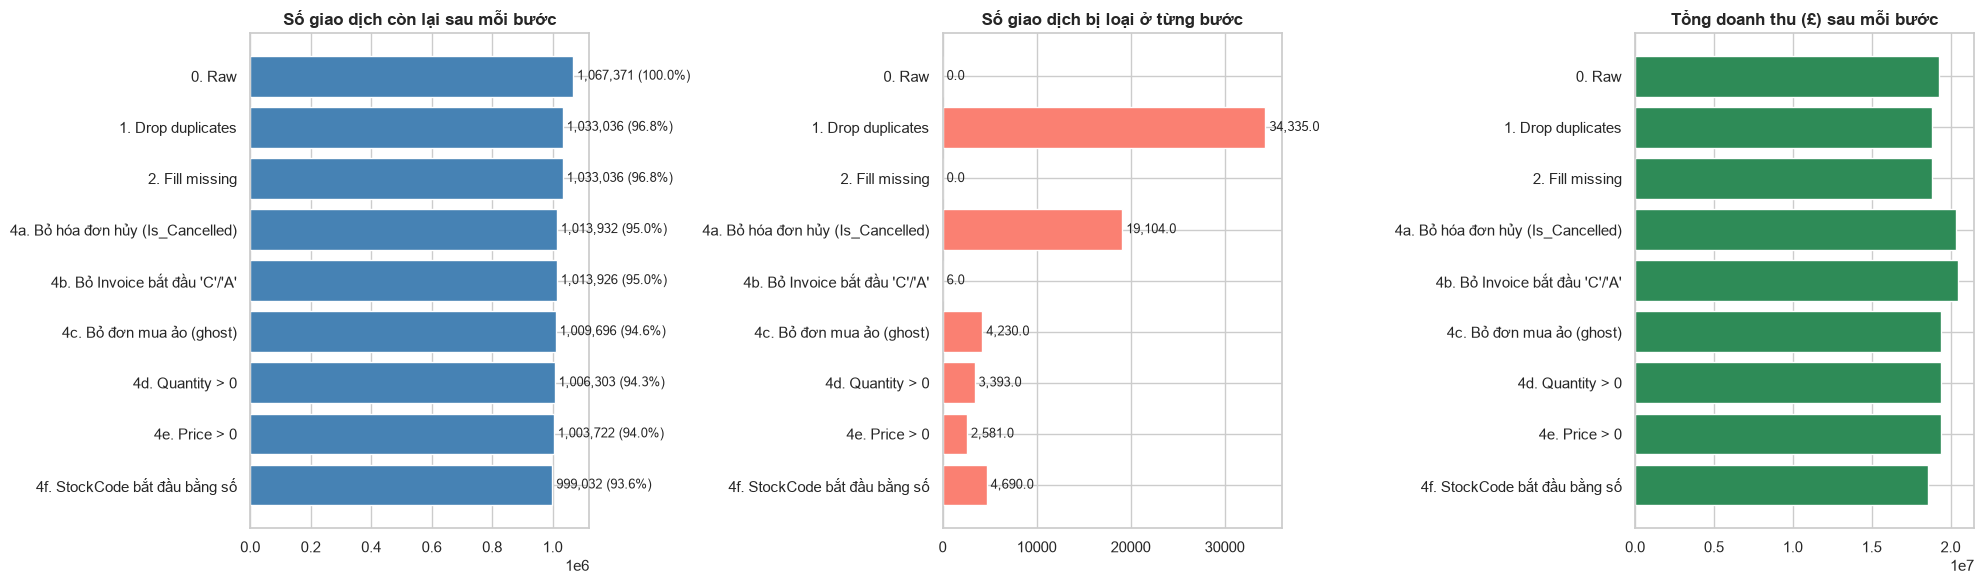

Kết quả cuối: 999,032 giao dịch sạch → 603 ngày kinh doanh.


In [11]:
log_df = pd.DataFrame(cleaning_log)
display(log_df)

print('LƯỢNG DỮ LIỆU CÒN LẠI SAU MỖI BƯỚC:')
display(log_df[['Bước', 'Đơn vị', 'Số dòng trước', 'Bị loại', 'Số dòng sau', 'Còn lại so với Raw (%)']])

tx = log_df[log_df['Đơn vị'] == 'giao dịch']
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

axes[0].barh(tx['Bước'], tx['Số dòng sau'], color='steelblue')
axes[0].invert_yaxis()
axes[0].set_title('Số giao dịch còn lại sau mỗi bước', fontweight='bold')
for i, (v, p) in enumerate(zip(tx['Số dòng sau'], tx['Còn lại so với Raw (%)'].fillna(100))):
    axes[0].text(v, i, f' {v:,} ({p:.1f}%)', va='center', fontsize=9)

axes[1].barh(tx['Bước'], tx['Bị loại'], color='salmon')
axes[1].invert_yaxis()
axes[1].set_title('Số giao dịch bị loại ở từng bước', fontweight='bold')
for i, v in enumerate(tx['Bị loại']):
    axes[1].text(v, i, f' {v:,}', va='center', fontsize=9)

axes[2].barh(tx['Bước'], tx['Doanh thu sau (£)'], color='seagreen')
axes[2].invert_yaxis()
axes[2].set_title('Tổng doanh thu (£) sau mỗi bước', fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Kết quả cuối: {len(df_clean):,} giao dịch sạch → {len(daily_sales)} ngày kinh doanh.')

In [ ]:
# Lưu dữ liệu sau khi clean vào folder output (OUTPUT_DIR khai báo ở Bước 0)
outputs = {
    'transactions_clean': df_clean,        # cấp giao dịch (sau Bước 4, có Revenue & Date)
    'daily_sales_clean': daily_sales,      # cấp ngày (sau Bước 7, có Log_Revenue, index = Date)
    'cleaning_log': log_df,                # nhật ký thay đổi qua từng bước
}

saved = []
for name, d in outputs.items():
    pkl_path = os.path.join(OUTPUT_DIR, f'{name}.pkl')
    csv_path = os.path.join(OUTPUT_DIR, f'{name}.csv')
    d.to_pickle(pkl_path)
    d.to_csv(csv_path, index=(name == 'daily_sales_clean'), encoding='utf-8-sig')
    for p in (pkl_path, csv_path):
        saved.append({'File': os.path.abspath(p), 'Số dòng': len(d), 'Số cột': d.shape[1],
                      'Dung lượng (MB)': round(os.path.getsize(p) / 1024**2, 2)})

display(pd.DataFrame(saved))

In [ ]:
# Lưu dữ liệu giao dịch đã clean ra file Excel (cùng tên với file gốc) trong folder output
# Lưu ý: ghi ~1 triệu dòng ra xlsx mất vài phút
XLSX_OUT = os.path.join(OUTPUT_DIR, 'online_retail_II.xlsx')
xlsx_cols = ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue']
df_xlsx = df_clean[xlsx_cols]

EXCEL_MAX_ROWS = 1_048_575  # giới hạn số dòng 1 sheet Excel (trừ dòng header)
with pd.ExcelWriter(XLSX_OUT, engine='openpyxl') as writer:
    if len(df_xlsx) <= EXCEL_MAX_ROWS:
        df_xlsx.to_excel(writer, sheet_name='clean', index=False)
        sheets = {'clean': len(df_xlsx)}
    else:
        # Vượt giới hạn thì tách theo năm
        sheets = {}
        for year, part in df_xlsx.groupby(df_xlsx['InvoiceDate'].dt.year):
            part.to_excel(writer, sheet_name=str(year), index=False)
            sheets[str(year)] = len(part)

display(pd.DataFrame({'Sheet': list(sheets.keys()), 'Số dòng': list(sheets.values())}))
print(f'Đã lưu: {os.path.abspath(XLSX_OUT)} ({os.path.getsize(XLSX_OUT) / 1024**2:.1f} MB)')